In [2]:
# import galstreams
# mws = galstreams.MWStreams(verbose=False)

import sys, pickle, os
from importlib import reload
from tqdm import tqdm, trange
os.environ["OMP_NUM_THREADS"] = "80"

import numpy as np, pandas as pd

import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm, LogNorm

import agama 
Gyr_to_AgamaTime = 1.0227 # 1 Gyr in Agama time units (kpc/(km/s))
import nbody_streams.agama_helper as ah

import emcee
#import corner

from astropy import units as u
import astropy.coordinates as coord
from astropy.coordinates import Galactocentric, ICRS, CartesianDifferential, CartesianRepresentation
from astropy import table

In [3]:
sys.path.append('../code/')
from coordinate_utils import get_rotation_matrix, sf_to_icrs, icrs_to_sf
from generate_sim_stream import create_stream_particle_spray
from stream_likelihood import log_likelihood, make_spline, log_prior, log_probability
from stream_data_utils import read_in_data

In [4]:
# Define file paths
BASE_POT_PATH = '../potential_files'
potMW_path = os.path.join(BASE_POT_PATH, 'McMillan17_nora.ini')
potLMC_path = os.path.join(BASE_POT_PATH, 'LMC_nora.ini')
accMW_path = os.path.join(BASE_POT_PATH, 'accMW')
trajLMC_path = os.path.join(BASE_POT_PATH, 'trajLMC')

## potential models to load
potMW = agama.Potential(file=potMW_path)
accMW = np.loadtxt(accMW_path)
trajLMC = np.loadtxt(trajLMC_path)
potacc  = agama.Potential(type='UniformAcceleration', file=accMW)
potLMC  = agama.Potential(file=potLMC_path)
potLMCm = agama.Potential(potential=potLMC, center=trajLMC)
potTotal= agama.Potential(potMW, potLMCm, potacc)

In [5]:
aau_member_path = '../data/aau_members.csv'
aau_distance_path = '../data/aau_bhb_rrl.csv'


aau_table = pd.read_csv(aau_member_path)
aau_bhb_rrl_data = pd.read_csv(aau_distance_path)

aau_bhb_rrl_data.columns = aau_bhb_rrl_data.columns.str.lower()

df_aau, prog_pars, prog_pars_icrs, df_distance_aau = read_in_data(aau_table, 'distance_modulus', aau_bhb_rrl_data)

In [6]:
def select_prog_pars(df, df_distance):
    select_phi1 = (df['phi1'] > 1.0) & (df['phi1'] < 10.0)
    select_distance = (df_distance['distance_modulus'].notna())
    select_dist_phi1 = (df_distance['phi1'] > 1.0) & (df_distance['phi1'] < 10.0)

    phi1med = np.median(df.loc[select_phi1,'phi1'])
    phi2med = np.median(df.loc[select_phi1,'phi2'])
    distmed = np.median(df_distance.loc[select_dist_phi1 & select_distance, 'distance_modulus'])
    ramed = np.median(df.loc[select_phi1,'ra'])
    decmed = np.median(df.loc[select_phi1,'dec'])
    pmramed = np.median(df.loc[select_phi1, 'pmra'])
    pmdecmed = np.median(df.loc[select_phi1, 'pmdec'])
    rvmed = np.median(df.loc[select_phi1, 'vel_calib'])

    prog_pars = [float(phi1med), float(phi2med), float(distmed), float(pmramed), float(pmdecmed), float(rvmed)]
    prog_pars_icrs = [float(ramed), float(decmed), float(distmed), float(pmramed), float(pmdecmed), float(rvmed)]

    return prog_pars, prog_pars_icrs

prog_pars_aau, prog_pars_icrs_aau = select_prog_pars(df_aau, df_distance_aau)

In [7]:
select_phi1 = df_aau['phi1'].values > -10.0
select_phi1_dist = df_distance_aau['phi1'].values > -10.0

data_dict_aau = dict(
    phi1_obs               = df_aau['phi1'].values[select_phi1],
    phi1_obs_dist          = df_distance_aau['phi1'].values[select_phi1_dist],
    phi2_obs               = df_aau['phi2'].values[select_phi1],
    rv_obs                 = df_aau['vel_calib'].values[select_phi1],
    rv_obs_errors          = df_aau['vel_calib_std'].values[select_phi1],
    dist_obs               = (10**((df_distance_aau['distance_modulus'].values + 5) / 5) / 1000)[select_phi1_dist],
    dist_obs_errors        = (10**((df_distance_aau['distance_modulus'].values + 5) / 5) / 1000 * 0.1)[select_phi1_dist],
    pmra_cosdec_obs        = df_aau['pmra'].values[select_phi1],
    pmra_cosdec_obs_errors = df_aau['pmra_error'].values[select_phi1],
    pmdec_obs              = df_aau['pmdec'].values[select_phi1],
    pmdec_obs_errors       = df_aau['pmdec_error'].values[select_phi1],
)

In [8]:
print(prog_pars)
print(prog_pars_icrs)
print(prog_pars_aau)
print(prog_pars_icrs_aau)

print(prog_pars_aau[2])
prog_pars_aau[2] = 10**((prog_pars_aau[2] - 10) / 5)
prog_pars_icrs_aau[2] = 10**((prog_pars_icrs_aau[2] - 10) / 5)

phi1_pos = 0
prog_pars_aau[0] = phi1_pos #FIXING PHI1 @ specified location on stream-track

prog_pars_icrs_aau[0] = phi1_pos

print(prog_pars_aau)
print(prog_pars_icrs_aau)

[1.3151519907855995, 0.8556910645897031, 16.744050585569173, -0.1891601021018523, -0.9768522127958916, -114.15299941957676]
[18.719708333333333, -26.09420277777778, 16.744050585569173, -0.1891601021018523, -0.9768522127958916, -114.15299941957676]
[5.190678685410779, 0.6120499540664559, 16.569262992576004, -0.3681949856011343, -1.028384787622473, -128.45714221025383]
[15.060556250000001, -24.0134875, 16.569262992576004, -0.3681949856011343, -1.028384787622473, -128.45714221025383]
16.569262992576004
[0, 0.6120499540664559, 20.599306449578684, -0.3681949856011343, -1.028384787622473, -128.45714221025383]
[0, -24.0134875, 20.599306449578684, -0.3681949856011343, -1.028384787622473, -128.45714221025383]


In [9]:
#Constructing stream progenitor present-day coordinates and information

prog_mass, prog_scaleradius =  20_000, 10/1_000 # Msun, kpc

num_particles = 2_000

Age_stream_inGyr = 5.0

R = np.array(
[
            [0.83697865, 0.29481904, -0.4610298],
            [0.51616778,-0.70514011, 0.4861566],
            [0.18176238, 0.64487142, 0.74236331],
        ])

aau_rot_matrix = u.Quantity(R, unit=u.dimensionless_unscaled)
#aau_rot_matrix = get_rotation_matrix('AAU-ATLAS-L21', mws = mws)

print(aau_rot_matrix)


[[ 0.83697865  0.29481904 -0.4610298 ]
 [ 0.51616778 -0.70514011  0.4861566 ]
 [ 0.18176238  0.64487142  0.74236331]]


In [10]:
print(data_dict_aau['phi1_obs_dist'].min(), data_dict_aau['phi1_obs_dist'].max())
phi1_obs_sel_dist = (data_dict_aau['phi1_obs_dist'] > -20) & (data_dict_aau['phi1_obs_dist'] < 20)
print(phi1_obs_sel_dist.sum())

-8.734498899129521 17.378968922864132
20


In [12]:
print(data_dict_aau['dist_obs'].shape)
print(data_dict_aau['phi1_obs_dist'].shape)
print(data_dict_aau['phi1_obs'].shape)

(20,)
(20,)
(88,)


In [13]:
#MCMC fit
nwalkers = 80
niter = 4000

#Taking a fraction of the prior range 
initial = prog_pars_aau[1:]
ndim = len(initial)
scales = np.array([0.01, 0.5, 0.01, 0.01, 1.0])  # phi2, dist, pmra, pmdec, rv
p0 = [np.array(initial) + scales * np.random.randn(ndim) for i in range(nwalkers)]
#p0 = [np.array(initial) + 1e-3 * np.random.randn(ndim) for i in range(nwalkers)]


data = (data_dict_aau, potTotal, prog_mass, prog_scaleradius, Age_stream_inGyr, num_particles, aau_rot_matrix)

def run_burnin(p0, nwalkers, ndim, log_probability, data, nburnin=500):
    sampler = emcee.EnsembleSampler(nwalkers, ndim, log_probability, args=data)
    print("Running burn-in...")
    p0, _, _ = sampler.run_mcmc(p0, nburnin, progress=True)
    print(f"Mean acceptance fraction: {np.mean(sampler.acceptance_fraction):.3f}")
    return sampler, p0

def run_production(p0, nwalkers, ndim, log_probability, data, niter=niter):
    sampler = emcee.EnsembleSampler(nwalkers, ndim, log_probability, args=data)
    print("Running production...")
    pos, prob, state = sampler.run_mcmc(p0, niter, progress=True)
    return sampler, pos, prob, state

In [14]:
# first burn-in
sampler_burnin, p0_burnin = run_burnin(p0, nwalkers, ndim, log_probability, data)
best = sampler_burnin.get_chain(flat=True)[np.argmax(sampler_burnin.get_log_prob(flat=True))]
print("Best params:", best)

# reinitialize and run second burn-in
p0_new = [best + scales * np.random.randn(ndim) for _ in range(nwalkers)]
sampler_burnin2, p0_burnin2 = run_burnin(p0_new, nwalkers, ndim, log_probability, data)
best2 = sampler_burnin2.get_chain(flat=True)[np.argmax(sampler_burnin2.get_log_prob(flat=True))]
print("Best params after 2nd burn-in:", best2)

# reinitialize around best and run production
p0_final = best2
p0_prod = [p0_final + scales * np.random.randn(ndim) for _ in range(nwalkers)]
sampler, pos, prob, state = run_production(p0_prod, nwalkers, ndim, log_probability, data)

Running burn-in...


  0%|          | 0/500 [00:00<?, ?it/s]

Prior rejection: [   0.5967186    17.59545844   -0.4006385    -1.00620982 -127.39007601]
Prior rejection: [   0.62175989   17.88162365   -0.35812061   -1.00856663 -125.95447924]


  0%|          | 1/500 [00:04<39:35,  4.76s/it]

Prior rejection: [   0.6004212    17.39790151   -0.39763512   -1.01386949 -125.99402213]


  1%|          | 4/500 [00:18<38:21,  4.64s/it]

... (2 outputs left out)

Mean acceptance fraction: 0.247
Best params: [   0.79697198   22.57552596   -0.14040426   -0.96083868 -109.83819112]
Running burn-in...


100%|██████████| 500/500 [38:48<00:00,  4.66s/it]


Mean acceptance fraction: 0.214
Best params after 2nd burn-in: [   0.80994489   22.60102683   -0.15174166   -0.95564016 -110.16829833]
Running production...


100%|██████████| 4000/4000 [5:17:07<00:00,  4.76s/it]  


In [19]:
#pulling out the values generated by the MCMC sampler XD
samples = sampler.flatchain
flat_samples = sampler.get_chain(flat=True)
flat_lnprob = sampler.get_log_prob(flat=True)
prog_pars_max = flat_samples[np.argmax(flat_lnprob)]
print(prog_pars_max)

phi2_best, dist_best, pmra_best, pmdec_best, rv_best = prog_pars_max

phi2_best, dist_best, pmra_best, pmdec_best, rv_best = prog_pars_max

prog_pars_best = np.concatenate([[0], prog_pars_max])

ra_best, dec_best = sf_to_icrs(0,phi2_best, aau_rot_matrix)

ra_best, dec_best = ra_best.item(), dec_best.item()

aau_c_best = coord.SkyCoord(
    ra=ra_best*u.degree, dec=dec_best*u.degree, distance=dist_best*u.kpc, 
    pm_ra_cosdec=pmra_best*u.mas/u.yr,
    pm_dec=pmdec_best*u.mas/u.yr,
    radial_velocity=rv_best*u.km/u.s
)

rep_best = aau_c_best.transform_to(coord.Galactocentric) # units here are kpc, km/s

prog_gal_best = np.array(
    [rep_best.x.value, rep_best.y.value, rep_best.z.value,
     rep_best.v_x.value, rep_best.v_y.value, rep_best.v_z.value]
) # units here are kpc, km/s

print(prog_pars_best, aau_c_best, prog_gal_best)

import os, json
import numpy as np

outdir = "/astro/users/shriyp/mcmc_results_11_26"
os.makedirs(outdir, exist_ok=True)

# --- Full chain info (arrays) ---
np.savez_compressed(
    f"{outdir}/aau_mcmc_results.npz",
    chain=sampler.get_chain(),            # (nsteps, nwalkers, ndim), unflattened
    log_prob=sampler.get_log_prob(),      # (nsteps, nwalkers)
    flat_samples=flat_samples,            # (nsteps*nwalkers, ndim)
    flat_lnprob=flat_lnprob,
    prog_pars_max=prog_pars_max,          # 5 free params (phi2, dist, pmra, pmdec, rv)
    prog_pars_best=prog_pars_best,        # with phi1=0 prepended
    prog_gal_best=prog_gal_best,          # Galactocentric x,y,z,vx,vy,vz (kpc, km/s)
    best_burnin1=best,
    best_burnin2=best2,
    scales=scales,
    ra_best=ra_best,
    dec_best=dec_best,
)

# --- Human-readable summary (scalars) ---
summary = {
    "param_names": ["phi2", "dist_kpc", "pmra_masyr", "pmdec_masyr", "rv_kms"],
    "prog_pars_max": prog_pars_max.tolist(),
    "ra_deg": float(ra_best),
    "dec_deg": float(dec_best),
    "prog_gal_best": {
        "x_kpc": float(prog_gal_best[0]), "y_kpc": float(prog_gal_best[1]),
        "z_kpc": float(prog_gal_best[2]), "vx_kms": float(prog_gal_best[3]),
        "vy_kms": float(prog_gal_best[4]), "vz_kms": float(prog_gal_best[5]),
    },
    "max_lnprob": float(flat_lnprob.max()),
    "nwalkers": int(nwalkers),
    "ndim": int(ndim),
}
with open(f"{outdir}/summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("Saved to", outdir)

[   0.81531601   22.57590704   -0.14132171   -0.96440628 -110.02010421]
[   0.            0.81531601   22.57590704   -0.14132171   -0.96440628
 -110.02010421] <SkyCoord (ICRS): (ra, dec, distance) in (deg, deg, kpc)
    (19.90469132, -26.77061389, 22.57590704)
 (pm_ra_cosdec, pm_dec, radial_velocity) in (mas / yr, mas / yr, km / s)
    (-0.14132171, -0.96440628, -110.02010421)> [-10.29324871  -1.28392865 -22.41374187  96.42033596 177.33596912
 114.316793  ]
Saved to /astro/users/shriyp/mcmc_results_11_26


In [2]:
import numpy as np

data = np.load("mcmc_results_11_26/aau_mcmc_results.npz")

print(data.files)  # list all saved keys

chain          = data["chain"]           # (nsteps, nwalkers, ndim)
log_prob       = data["log_prob"]        # (nsteps, nwalkers)
flat_samples   = data["flat_samples"]    # (nsteps*nwalkers, ndim)
flat_lnprob    = data["flat_lnprob"]
prog_pars_max  = data["prog_pars_max"]   # 5 free params
prog_pars_best = data["prog_pars_best"]  # phi1=0 prepended (6 values)
prog_gal_best  = data["prog_gal_best"]   # x,y,z,vx,vy,vz
ra_best        = float(data["ra_best"])  # 0-d arrays -> convert to float
dec_best       = float(data["dec_best"])
scales         = data["scales"]
best_burnin1   = data["best_burnin1"]
best_burnin2   = data["best_burnin2"]

['chain', 'log_prob', 'flat_samples', 'flat_lnprob', 'prog_pars_max', 'prog_pars_best', 'prog_gal_best', 'best_burnin1', 'best_burnin2', 'scales', 'ra_best', 'dec_best']


NameError: name 'plt' is not defined

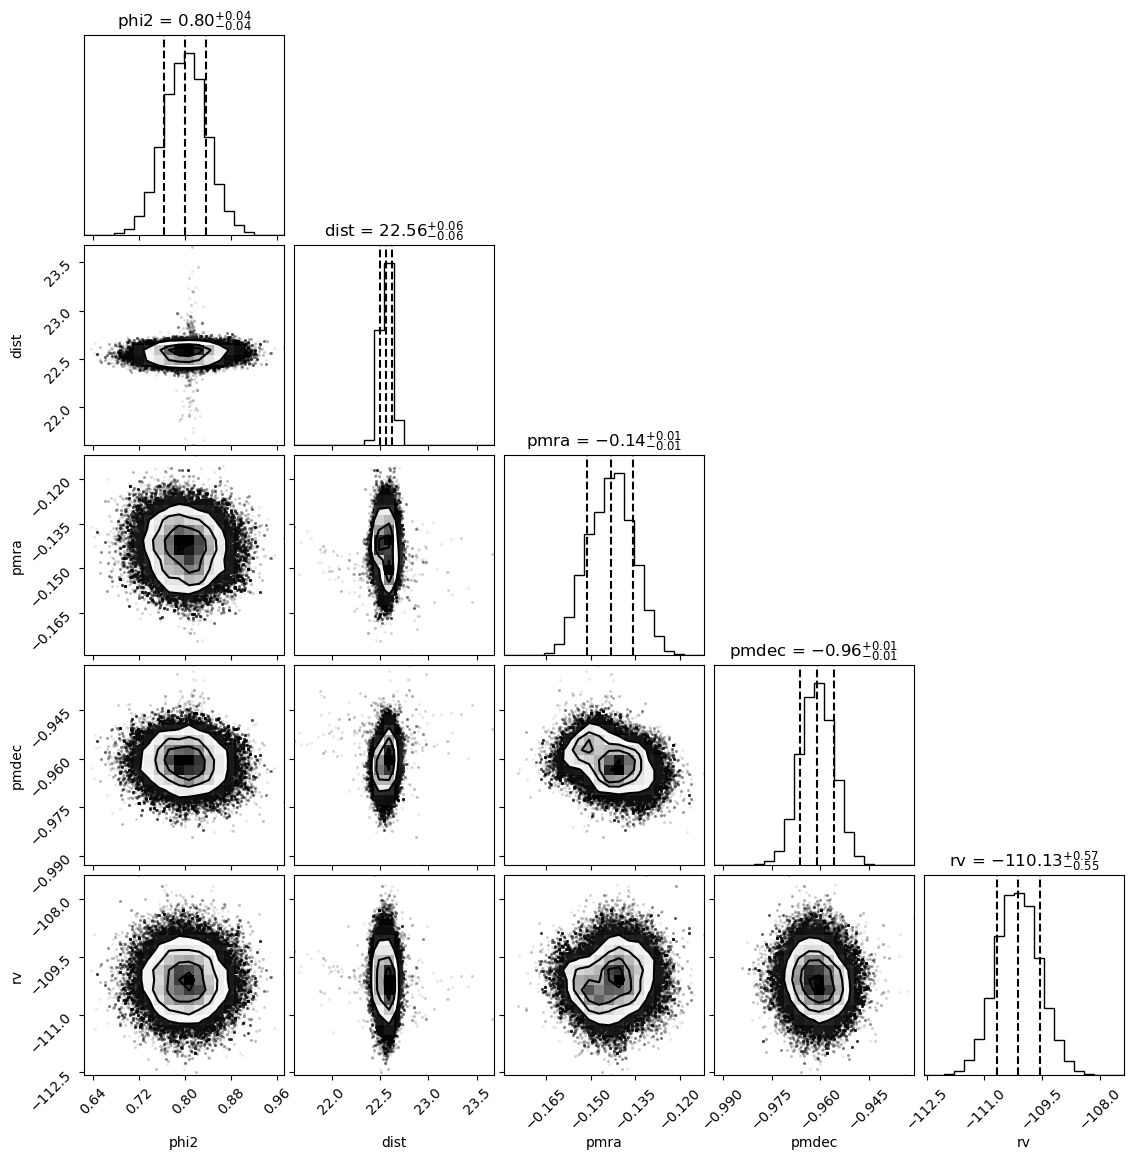

In [5]:
import matplotlib.style.core  # makes mpl.style.core available as an attribute
import corner as corner
#MCMC checks!
labels = ['phi2', 'dist', 'pmra', 'pmdec', 'rv']

fig = corner.corner(
    flat_samples,
    labels=labels,
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    title_kwargs={"fontsize": 12},
 fig_kwargs={'figsize': (4, 4)}
)
plt.savefig('atlas_unperturbed_corner_11_22_2026.pdf')
plt.show()

In [13]:
#generate the stream with best_fit_params
gen_best_stream = create_stream_particle_spray(
    pot_host=potTotal, 
    initmass=prog_mass, 
    scaleradius=prog_scaleradius, 
    prog_pot_kind='Plummer', 
    sat_cen_present=prog_gal_best, 
    num_particles=num_particles,
    time_end=0.0, 
    time_total=Age_stream_inGyr, save_rate=1,
    #add_perturber={'mass':0},
)

#Cleaning up our coordinate frames *whistles nonchalantly*
best_stream_model = gen_best_stream['part_xv']

galcen_best_stream = coord.Galactocentric(
        x=best_stream_model[:,0] * u.kpc,
        y=best_stream_model[:,1] * u.kpc,
        z=best_stream_model[:,2] * u.kpc,
        v_x=best_stream_model[:,3] * u.km/u.s,
        v_y=best_stream_model[:,4] * u.km/u.s,
        v_z=best_stream_model[:,5] * u.km/u.s,
        representation_type='cartesian',
        differential_type='cartesian'
    )

icrs_best_stream = galcen_best_stream.transform_to(coord.ICRS())

ra_max = icrs_best_stream.ra.value
dec_max = icrs_best_stream.dec.value
dist_max = icrs_best_stream.distance.value
pmra_max = icrs_best_stream.pm_ra_cosdec.value
pmdec_max = icrs_best_stream.pm_dec.value
rv_max = icrs_best_stream.radial_velocity.value

phi1_max, phi2_max = icrs_to_sf(ra_max, dec_max, aau_rot_matrix)

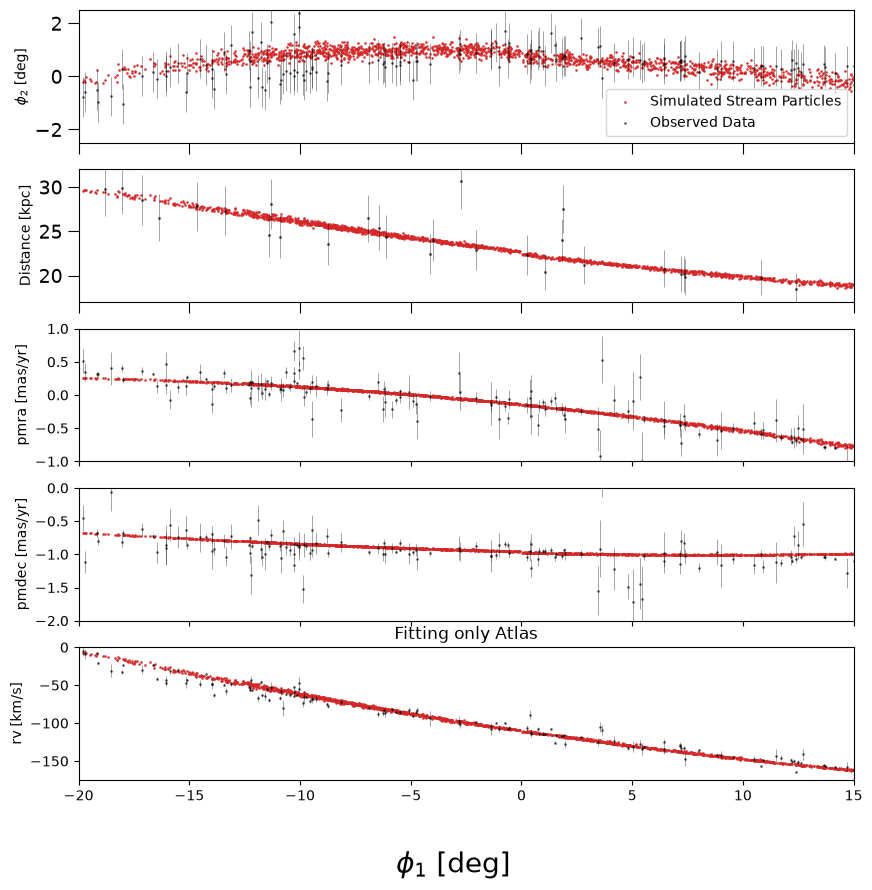

In [14]:
#plot with best-fit progenitor IC's from MCMC!

fig, ax = plt.subplots(5,1, sharex = True)
fig.set_size_inches(10,10)
fig.supxlabel(r'$\phi_1$ [deg]',fontsize=20)
ax[-1].set_xlim(-20,15)
ax[-1].set_title(label ='Fitting only Atlas',loc='center' )
#simulation
ax[0].scatter(phi1_max, phi2_max,s=0.75,color='tab:red', alpha= 0.9, label = 'Simulated Stream Particles')
ax[0].tick_params(axis='both', which='major', labelsize=14., length=8)
ax[0].tick_params(axis='both', which='minor', length=3)
ax[0].set_ylim(-2.5,2.5)

ax[0].set_ylabel(r'$\phi_2$ [deg]', fontsize=10)
ax[1].scatter(phi1_max, dist_max,s=0.75,color='tab:red',alpha= 0.9 )
ax[1].tick_params(axis='both', which='major', labelsize=14., length=8)
ax[1].tick_params(axis='both', which='minor', length=3)
ax[1].set_ylabel('Distance [kpc]', fontsize=10)
ax[1].set_ylim(17,32)

ax[2].scatter(phi1_max, pmra_max,s=0.75,color='tab:red',alpha= 0.9 )
ax[2].set_ylim(-1,1)
ax[2].set_ylabel('pmra [mas/yr]', fontsize=10)

ax[3].scatter(phi1_max, pmdec_max,s=0.75,color='tab:red',alpha= 0.9 )
ax[3].set_ylabel('pmdec [mas/yr]', fontsize=10)
ax[3].set_ylim(-2,0)

ax[4].scatter(phi1_max, rv_max,s=0.75,color='tab:red',alpha= 0.9)
ax[4].set_ylabel('rv [km/s]', fontsize=10)
ax[4].set_ylim(-175,0)

#data
ax[0].scatter(df_aau['phi1'], df_aau['phi2'] , s=1,color='k', alpha = 0.5, label = 'Observed Data')
ax[0].errorbar(df_aau['phi1'], df_aau['phi2'], yerr=np.nanstd(df_aau['phi2']), fmt='none', ecolor='k', alpha = 0.5, capsize=0, capthick=0.7, elinewidth=0.5)

ax[1].scatter(df_distance_aau['phi1'],(10**((df_distance_aau['distance_modulus'])/5 +1)*1e-3),s=1.5,color='k', alpha = 0.5)
ax[1].errorbar(df_distance_aau['phi1'],(10**((df_distance_aau['distance_modulus'])/5 +1)*1e-3), yerr=np.abs(((10**((df_distance_aau['distance_modulus'])/5 +1)*1e-3))*0.1), fmt='none', ecolor='k',alpha = 0.5,capsize=0, capthick=0.7, elinewidth=0.5)


ax[2].scatter(df_aau['phi1'], df_aau['pmra'],s=1,color='k', alpha = 0.5)
ax[2].errorbar(df_aau['phi1'], df_aau['pmra'], yerr=df_aau['pmra_error'], fmt='none', ecolor='k',alpha = 0.5,capsize=0, capthick=0.7, elinewidth=0.5)

ax[3].scatter(df_aau['phi1'], df_aau['pmdec'],s=1,color='k',alpha = 0.5)
ax[3].errorbar(df_aau['phi1'], df_aau['pmdec'], yerr=df_aau['pmdec_error'], fmt='none', ecolor='k', alpha = 0.5, capsize=0, capthick=0.7, elinewidth=0.5)

ax[4].scatter(df_aau['phi1'], df_aau['vel_calib'],s=1,color='k', alpha = 0.5)
ax[4].errorbar(df_aau['phi1'], df_aau['vel_calib'], yerr=df_aau['vel_calib_std'], fmt='none', ecolor='k',alpha = 0.5, capsize=0, capthick=0.7, elinewidth=0.5)

ax[0].legend(loc = 'lower right')
#plt.savefig('atlas_unperturbed_6_17_2026.pdf')